# 09 — Análise comparativa, respostas e recomendação

Este notebook fecha a atividade. Ele **não treina nada novo**: integra as
tabelas produzidas pelos notebooks 06 (métricas), 07 (generalização e
validação cruzada) e 08 (eficiência computacional) em uma única
tabela-resumo e responde às perguntas (a)–(f) do enunciado para os dois
problemas, com evidências numéricas.

A separação entre medida e estimativa é mantida: tempos e memórias vêm do
notebook 08; energia e CO₂ são estimativas `P × t`; o esforço humano vem
de `logs/cronometro_regras.csv` e está **incompleto para a regressão**.

In [1]:
from pathlib import Path
import sys
import warnings

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import *
from rules.regras_classificacao import REGRAS_CLASSIFICACAO
from rules.regras_regressao import REGRAS_REGRESSAO

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
criar_diretorios()

# ---------------------------------------------------------------------------
# Leitura das saídas já produzidas pelos notebooks 06, 07 e 08.
# Este notebook NÃO retreina nem reavalia modelos: ele apenas integra os
# resultados, de modo que a análise final não introduza novos números.
# ---------------------------------------------------------------------------
perf_c = pd.read_csv(TABLES_DIR / "desempenho_classificacao.csv", encoding="utf-8")
perf_c["Modelo"] = perf_c["Modelo"].str.replace(
    r"\s*\(cobertura.*\)$", "", regex=True
)
perf_c["Modelo"] = perf_c["Modelo"].replace({"Sistema Especialista": "Especialista"})

perf_r = pd.read_csv(TABLES_DIR / "desempenho_regressao.csv", encoding="utf-8")
perf_r["Modelo"] = perf_r["Modelo"].replace(
    {
        "Especialista v1 (4 células)": "Especialista v1",
        "Especialista v2 (19 faixas)": "Especialista v2",
    }
)

gen_c = pd.read_csv(TABLES_DIR / "generalizacao_classificacao.csv", encoding="utf-8")
gen_c["Modelo"] = gen_c["Modelo"].replace({"Sistema Especialista": "Especialista"})

gen_r = pd.read_csv(TABLES_DIR / "generalizacao_regressao.csv", encoding="utf-8")
gen_r["Modelo"] = gen_r["Modelo"].replace(
    {
        "Especialista v1 (4 células)": "Especialista v1",
        "Especialista v2 (19 faixas)": "Especialista v2",
    }
)

cv = pd.read_csv(TABLES_DIR / "validacao_cruzada.csv", encoding="utf-8")
cv["Modelo"] = cv["Modelo"].replace(
    {
        "Sistema Especialista": "Especialista",
        "Especialista v2 (19 faixas)": "Especialista v2",
    }
)

ef = pd.read_csv(TABLES_DIR / "eficiencia_computacional.csv", encoding="utf-8")
ef["Modelo"] = ef["Modelo"].replace(
    {
        "Especialista (classificação)": "Especialista",
        "Especialista v2 (regressão)": "Especialista v2",
        "Árvore de Decisão (classificação)": "Árvore de Decisão",
        "Árvore de Decisão (regressão)": "Árvore de Decisão",
        "Random Forest (classificação)": "Random Forest",
        "Random Forest (regressão)": "Random Forest",
        "Gradient Boosting (classificação)": "Gradient Boosting",
        "Gradient Boosting (regressão)": "Gradient Boosting",
    }
)

subconjunto = pd.read_csv(
    TABLES_DIR / "desempenho_classificacao_subconjunto.csv", encoding="utf-8"
)
comparacao_features = pd.read_csv(
    TABLES_DIR / "comparacao_features_regras.csv", encoding="utf-8"
)
importancias = pd.read_csv(TABLES_DIR / "importancia_features.csv", encoding="utf-8")

print("Tabelas carregadas de:", TABLES_DIR)
print("Classificação (teste completo):", perf_c.shape[0], "modelos")
print("Regressão:", perf_r.shape[0], "modelos")

Tabelas carregadas de: C:\Users\lucas\OneDrive\Documentos\avaliacao-comparativa-modelos-ia\reports\tables
Classificação (teste completo): 4 modelos
Regressão: 5 modelos


## 1. Tabela-resumo final

A tabela reúne, por modelo: métrica principal no teste, média e desvio da
validação cruzada de 5 folds, gap de generalização, cobertura (quando
aplicável) e custo computacional. A métrica principal é **F1-Score macro**
na classificação e **MAE** na regressão; o gap é sempre positivo quando há
piora do treino para o teste.

O especialista de classificação é avaliado no teste completo, mas só
responde a 53,87% dos registros; por isso a cobertura é explicitada. A
comparação justa no subconjunto comum aparece na Seção 2.

In [2]:
def buscar(df, modelo, coluna, **filtros):
    sub = df[df["Modelo"] == modelo]
    for chave, valor in filtros.items():
        sub = sub[sub[chave] == valor]
    if sub.empty or coluna not in sub.columns:
        return np.nan
    return sub.iloc[0][coluna]

def linha_resumo(problema, modelo):
    if problema == "Classificação":
        metrica = "F1-Score Macro"
        valor = buscar(perf_c, modelo, "F1-Score (Macro)")
        nome_secundaria = "Accuracy"
        secundaria = buscar(perf_c, modelo, "Accuracy")
        gap = buscar(gen_c, modelo, "Gap F1 (Treino−Teste)")
        cobertura = 100 * buscar(gen_c, modelo, "Cobertura Teste")
    else:
        metrica = "MAE"
        valor = buscar(perf_r, modelo, "MAE Teste")
        nome_secundaria = "R²"
        secundaria = buscar(perf_r, modelo, "R2 Teste")
        gap = buscar(gen_r, modelo, "Gap MAE (Teste−Treino)")
        cobertura = np.nan

    cv_media = buscar(cv, modelo, "Média", Problema=problema)
    cv_dp = buscar(cv, modelo, "CV DP", Problema=problema)

    return {
        "Problema": problema,
        "Modelo": modelo,
        "Origem": "Regras" if "Especialista" in modelo else "ML",
        "Métrica": metrica,
        "Valor Teste": valor,
        "Métrica Secundária": nome_secundaria,
        "Valor Secundário": secundaria,
        "CV Média": cv_media,
        "CV DP": cv_dp,
        "Gap Generalização": gap,
        "Cobertura Teste (%)": cobertura,
        "Tempo Treino (s)": buscar(ef, modelo, "Tempo de Treino (s)", Problema=problema),
        "Pico RAM Treino (MiB)": buscar(ef, modelo, "Pico RAM Treino (MiB)", Problema=problema),
        "Tempo/amostra (ms)": buscar(ef, modelo, "Tempo por Amostra (ms)", Problema=problema),
        "Vazão (amostras/s)": buscar(ef, modelo, "Vazão (amostras/s)", Problema=problema),
        "Pico RAM Inferência (MiB)": buscar(ef, modelo, "Pico RAM Inferência (MiB)", Problema=problema),
        "Tamanho (KiB)": buscar(ef, modelo, "Tamanho (KiB)", Problema=problema),
        "Energia Treino (kWh)": buscar(ef, modelo, "Energia Treino (kWh)", Problema=problema),
        "CO2 Treino (g)": buscar(ef, modelo, "CO2 Treino (g)", Problema=problema),
        "Energia 1M (kWh)": buscar(ef, modelo, "Energia Inferência 1M (kWh)", Problema=problema),
        "CO2 1M (g)": buscar(ef, modelo, "CO2 Inferência 1M (g)", Problema=problema),
        "Esforço Humano (min)": buscar(ef, modelo, "Esforço Humano (min)", Problema=problema),
    }

modelos_c = ["Especialista", "Árvore de Decisão", "Random Forest", "Gradient Boosting"]
modelos_r = [
    "Especialista v1",
    "Especialista v2",
    "Árvore de Decisão",
    "Random Forest",
    "Gradient Boosting",
]

resumo = pd.DataFrame(
    [linha_resumo("Classificação", m) for m in modelos_c]
    + [linha_resumo("Regressão", m) for m in modelos_r]
)

# Ordena por desempenho dentro de cada problema (F1 maior; MAE menor).
partes = []
for problema, ascendente in [("Classificação", False), ("Regressão", True)]:
    parte = resumo[resumo["Problema"] == problema].sort_values(
        "Valor Teste", ascending=ascendente
    )
    partes.append(parte)
resumo = pd.concat(partes).reset_index(drop=True)

observacoes = {
    ("Classificação", "Especialista"): "Cobertura 53,87%; 3 sessões cronometradas.",
    ("Regressão", "Especialista v1"): "Baseline; fora da recomendação.",
    ("Regressão", "Especialista v2"): "Esforço de 68,22 min refere-se à v1; v2 não cronometrada.",
}
resumo["Observação"] = [
    observacoes.get(
        (linha["Problema"], linha["Modelo"]),
        "Refit final; busca de hiperparâmetros não cronometrada."
        if linha["Origem"] == "ML"
        else "",
    )
    for _, linha in resumo.iterrows()
]

colunas = [
    "Problema",
    "Modelo",
    "Origem",
    "Métrica",
    "Valor Teste",
    "Métrica Secundária",
    "Valor Secundário",
    "CV Média",
    "CV DP",
    "Gap Generalização",
    "Cobertura Teste (%)",
    "Tempo Treino (s)",
    "Pico RAM Treino (MiB)",
    "Tempo/amostra (ms)",
    "Vazão (amostras/s)",
    "Pico RAM Inferência (MiB)",
    "Tamanho (KiB)",
    "Energia Treino (kWh)",
    "CO2 Treino (g)",
    "Energia 1M (kWh)",
    "CO2 1M (g)",
    "Esforço Humano (min)",
    "Observação",
]
resumo = resumo[colunas]
resumo.to_csv(
    TABLES_DIR / "resumo_final.csv", index=False, encoding="utf-8", na_rep="N/A"
)

colunas_exibir = [
    "Problema",
    "Modelo",
    "Valor Teste",
    "CV Média",
    "CV DP",
    "Gap Generalização",
    "Cobertura Teste (%)",
    "Tempo Treino (s)",
    "Tempo/amostra (ms)",
    "Tamanho (KiB)",
    "Energia Treino (kWh)",
    "Energia 1M (kWh)",
    "Esforço Humano (min)",
]
display(resumo[colunas_exibir].round(4))
print("Tabela salva em", TABLES_DIR / "resumo_final.csv")

,Problema,Modelo,Valor Teste,CV Média,CV DP,Gap Generalização,Cobertura Teste (%),Tempo Treino (s),Tempo/amostra (ms),Tamanho (KiB),Energia Treino (kWh),Energia 1M (kWh),Esforço Humano (min)
0,Classificação,Random Forest,0.6862,0.6838,0.0247,0.3138,100.00,1.0421,0.0142,70780.7598,0.0000,0.0003,NaN
1,Classificação,Gradient Boosting,0.6681,0.7126,0.0200,0.0826,100.00,39.3747,0.0082,774.5186,0.0007,0.0001,NaN
2,Classificação,Árvore de Decisão,0.6649,0.6781,0.0300,0.0823,100.00,0.2901,0.0022,130.8311,0.0000,0.0000,NaN
3,Classificação,Especialista,0.5618,0.5687,0.0122,0.0070,53.87,NaN,0.0056,0.7852,NaN,0.0001,152.4500
4,Regressão,Gradient Boosting,5.9278,5.9188,0.0316,0.0461,NaN,7.7824,0.0031,157.0176,0.0001,0.0001,NaN
5,Regressão,Especialista v2,5.9941,5.9903,0.0413,0.0039,NaN,NaN,0.0057,1.9541,NaN,0.0001,68.2167
6,Regressão,Random Forest,6.1402,6.1172,0.0407,1.5487,NaN,1.4683,0.0182,112040.1348,0.0000,0.0003,NaN
7,Regressão,Árvore de Decisão,6.2824,6.3585,0.0355,0.4545,NaN,0.1740,0.0017,115.4404,0.0000,0.0000,NaN
8,Regressão,Especialista v1,11.2721,NaN,NaN,0.0263,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Tabela salva em C:\Users\lucas\OneDrive\Documentos\avaliacao-comparativa-modelos-ia\reports\tables\resumo_final.csv


**Leitura.** Os valores de F1 e MAE confirmam a hierarquia dos notebooks
anteriores: na classificação, Random Forest e Gradient Boosting estão
empatados na prática; na regressão, Gradient Boosting lidera e o
especialista v2 vem logo atrás. A coluna de esforço humano torna visível
o custo que não aparece no tempo de CPU: 152,45 min para as regras de
classificação e 68,22 min (parciais) para as de regressão.

## 2. Pergunta (a) — melhor desempenho no teste e relevância da diferença

Para julgar se a diferença é relevante, comparamos a diferença observada
com o desvio padrão da validação cruzada. A razão
`Δ / DP combinado` usa `DP combinado = sqrt(DP₁² + DP₂²)`; valores abaixo
de ~2 indicam que a diferença cabe dentro da variabilidade dos folds.

In [3]:
def tabela_diferencas(problema, maior_melhor):
    sub = resumo[resumo["Problema"] == problema].copy()
    sub = sub.sort_values(
        "Valor Teste", ascending=not maior_melhor
    ).reset_index(drop=True)
    melhor = sub.iloc[0]
    sub["Delta vs melhor"] = sub["Valor Teste"] - melhor["Valor Teste"]
    sub["DP combinado"] = np.sqrt(sub["CV DP"] ** 2 + melhor["CV DP"] ** 2)
    sub["Delta / DP combinado"] = sub["Delta vs melhor"] / sub["DP combinado"]
    return sub[
        [
            "Modelo",
            "Valor Teste",
            "CV Média",
            "CV DP",
            "Delta vs melhor",
            "DP combinado",
            "Delta / DP combinado",
        ]
    ]

print("CLASSIFICAÇÃO — F1-Score macro (maior é melhor)")
display(tabela_diferencas("Classificação", True).round(4))
print("REGRESSÃO — MAE (menor é melhor)")
display(tabela_diferencas("Regressão", False).round(4))

print("Subconjunto comum: apenas registros classificados pelo especialista")
display(
    subconjunto[
        ["Modelo", "Accuracy", "F1-Score (Macro)", "F1-Score (High)"]
    ].round(4)
)

CLASSIFICAÇÃO — F1-Score macro (maior é melhor)


,Modelo,Valor Teste,CV Média,CV DP,Delta vs melhor,DP combinado,Delta / DP combinado
0,Random Forest,0.6862,0.6838,0.0247,0.0000,0.0349,0.0000
1,Gradient Boosting,0.6681,0.7126,0.0200,-0.0181,0.0318,-0.5699
2,Árvore de Decisão,0.6649,0.6781,0.0300,-0.0212,0.0388,-0.5471
3,Especialista,0.5618,0.5687,0.0122,-0.1244,0.0275,-4.5166


REGRESSÃO — MAE (menor é melhor)


,Modelo,Valor Teste,CV Média,CV DP,Delta vs melhor,DP combinado,Delta / DP combinado
0,Gradient Boosting,5.9278,5.9188,0.0316,0.0000,0.0447,0.0000
1,Especialista v2,5.9941,5.9903,0.0413,0.0663,0.0520,1.2754
2,Random Forest,6.1402,6.1172,0.0407,0.2124,0.0516,4.1188
3,Árvore de Decisão,6.2824,6.3585,0.0355,0.3546,0.0475,7.4629
4,Especialista v1,11.2721,NaN,NaN,5.3443,NaN,NaN


Subconjunto comum: apenas registros classificados pelo especialista


,Modelo,Accuracy,F1-Score (Macro),F1-Score (High)
0,Sistema Especialista,0.8766,0.5618,0.9539
1,Árvore de Decisão,0.9244,0.7018,0.9632
2,Random Forest,0.9244,0.7310,0.9610
3,Gradient Boosting,0.9304,0.7124,0.9654


**Classificação.** A Random Forest tem o melhor F1 macro no teste
(0,6862), contra 0,6681 do Gradient Boosting, 0,6649 da árvore e 0,5618
do especialista. A vantagem sobre o Gradient Boosting é de 0,0181, menor
que um desvio padrão da CV (0,0247 e 0,0200) e cerca de 0,6 DP combinado:
**não é uma diferença estatisticamente clara**. No entanto, a CV conta
outra história: o Gradient Boosting tem a melhor média (0,7126 ± 0,0200),
contra 0,6838 ± 0,0247 da Random Forest. Ou seja, o RF ganha por pouco em
uma única divisão, mas o GB é mais consistente entre folds e tem a melhor
accuracy (0,8790).

O especialista tem accuracy alta (0,8766), mas ela é medida em 53,87% dos
casos. No subconjunto comum, os modelos de ML continuam à frente no F1
macro (RF 0,7310; GB 0,7124; árvore 0,7018) e o especialista fica em
0,5618. Portanto, a diferença **não é apenas cobertura**: as regras erram
mais as fronteiras entre *Moderate* e *High*. Em compensação, o
especialista tem o melhor F1 da classe *High* (0,9539), que é a classe de
maior custo clínico.

**Regressão.** O Gradient Boosting tem o menor MAE (5,9278) e o maior R²
(0,7745). A diferença para o especialista v2 (5,9941; R² 0,7655) é de
0,0663 no MAE, cerca de 1,3 DP combinado — pequena, mas consistente, pois
o GB também lidera na CV (5,9188 ± 0,0316 contra 5,9903 ± 0,0413). A
Random Forest (6,1402) e a árvore (6,2824) ficam atrás; a v1 (11,2721) é
claramente inadequada e serve apenas como linha de base.

## 3. Pergunta (b) — qual modelo generaliza melhor?

Generalização é lida pelo gap treino→teste e pela estabilidade entre
folds. Um gap grande com desempenho de teste medíocre indica
overfitting; um gap pequeno com desempenho baixo pode indicar
subajuste ou, no caso do especialista, ausência de aprendizado.

In [4]:
gap_c = gen_c[
    [
        "Modelo",
        "F1 Macro Treino",
        "F1 Macro Teste",
        "Gap F1 (Treino−Teste)",
        "Cobertura Teste",
    ]
].copy()
gap_r = gen_r[
    [
        "Modelo",
        "MAE Treino",
        "MAE Teste",
        "Gap MAE (Teste−Treino)",
        "R2 Treino",
        "R2 Teste",
        "Gap R2 (Treino−Teste)",
    ]
].copy()

print("CLASSIFICAÇÃO — gap de F1 macro")
display(gap_c.round(4))
print("REGRESSÃO — gaps de MAE e R²")
display(gap_r.round(4))

CLASSIFICAÇÃO — gap de F1 macro


,Modelo,F1 Macro Treino,F1 Macro Teste,Gap F1 (Treino−Teste),Cobertura Teste
0,Especialista,0.5688,0.5618,0.0070,0.5387
1,Árvore de Decisão,0.7473,0.6649,0.0823,1.0000
2,Random Forest,1.0000,0.6862,0.3138,1.0000
3,Gradient Boosting,0.7506,0.6681,0.0826,1.0000


REGRESSÃO — gaps de MAE e R²


,Modelo,MAE Treino,MAE Teste,Gap MAE (Teste−Treino),R2 Treino,R2 Teste,Gap R2 (Treino−Teste)
0,Especialista v1,11.2458,11.2721,0.0263,0.2054,0.1964,0.0089
1,Especialista v2,5.9902,5.9941,0.0039,0.7667,0.7655,0.0012
2,Árvore de Decisão,5.8279,6.2824,0.4545,0.7813,0.7429,0.0384
3,Random Forest,4.5915,6.1402,1.5487,0.8626,0.7569,0.1057
4,Gradient Boosting,5.8817,5.9278,0.0461,0.7794,0.7745,0.0049


**Classificação.** A Random Forest é o caso clássico de overfitting:
F1 de treino 0,99998 contra 0,6862 no teste, gap de 0,3138. A árvore e o
Gradient Boosting têm gaps praticamente iguais (0,0823 e 0,0826) e
desempenho de teste semelhante. O especialista tem o menor gap (0,0070),
mas isso reflete uma base fixa, não aprendizado: o F1 de treino e teste é
o mesmo por construção, e a CV é calculada apenas na parte coberta. Entre
os modelos que aprendem, **Gradient Boosting e árvore generalizam melhor**;
o GB leva vantagem por ter média de CV mais alta e menor variância.

**Regressão.** O especialista v2 tem o menor gap de MAE (0,0039) e de R²
(0,0012), seguido de perto pelo Gradient Boosting (0,0461 e 0,0049). A
árvore (0,4545) e a Random Forest (1,5487) pioram muito do treino para o
teste; a RF é a que mais decora (R² de treino 0,8626 contra 0,7569 no
teste). Em termos de **generalização absoluta**, o Gradient Boosting é o
melhor compromisso: gap pequeno e o melhor erro de teste. O especialista
v2 é o mais estável, mas seu erro é ligeiramente maior.

## 4. Pergunta (c) — eficiência computacional e trade-off

A eficiência tem quatro dimensões: tempo de treino, tempo de inferência,
memória e tamanho do artefato. A energia é proporcional ao tempo
(estimativa), então acompanha as conclusões.

In [5]:
colunas_ef = [
    "Problema",
    "Modelo",
    "Tempo Treino (s)",
    "Pico RAM Treino (MiB)",
    "Tempo/amostra (ms)",
    "Vazão (amostras/s)",
    "Pico RAM Inferência (MiB)",
    "Tamanho (KiB)",
    "Energia Treino (kWh)",
    "Energia 1M (kWh)",
]
display(
    resumo[colunas_ef]
    .sort_values(["Problema", "Tempo/amostra (ms)"])
    .round(6)
)

def pegar(problema, modelo):
    return resumo[
        (resumo["Problema"] == problema) & (resumo["Modelo"] == modelo)
    ].iloc[0]

rf_c, gb_c = pegar("Classificação", "Random Forest"), pegar("Classificação", "Gradient Boosting")
rf_r, gb_r = pegar("Regressão", "Random Forest"), pegar("Regressão", "Gradient Boosting")
esp_c, esp_r = pegar("Classificação", "Especialista"), pegar("Regressão", "Especialista v2")

print(f"RF/GB — tamanho: {rf_c['Tamanho (KiB)'] / gb_c['Tamanho (KiB)']:.0f}x (cls) e {rf_r['Tamanho (KiB)'] / gb_r['Tamanho (KiB)']:.0f}x (reg)")
print(f"RF/GB — tempo de treino: {rf_c['Tempo Treino (s)'] / gb_c['Tempo Treino (s)']:.2f}x (cls)")
print(f"RF/GB — inferência: {rf_c['Tempo/amostra (ms)'] / gb_c['Tempo/amostra (ms)']:.2f}x (cls) e {rf_r['Tempo/amostra (ms)'] / gb_r['Tempo/amostra (ms)']:.2f}x (reg)")
print(f"Especialista/GB — tamanho: {esp_c['Tamanho (KiB)'] / gb_c['Tamanho (KiB)']:.3f}x (cls) e {esp_r['Tamanho (KiB)'] / gb_r['Tamanho (KiB)']:.3f}x (reg)")

,Problema,Modelo,Tempo Treino (s),Pico RAM Treino (MiB),Tempo/amostra (ms),Vazão (amostras/s),Pico RAM Inferência (MiB),Tamanho (KiB),Energia Treino (kWh),Energia 1M (kWh)
2,Classificação,Árvore de Decisão,0.290114,9.190372,0.002190,456614.541019,2.694813,130.831055,0.000005,0.000040
3,Classificação,Especialista,NaN,NaN,0.005626,177760.333554,2.096405,0.785156,NaN,0.000102
1,Classificação,Gradient Boosting,39.374735,12.334444,0.008245,121279.645801,2.975504,774.518555,0.000711,0.000149
0,Classificação,Random Forest,1.042075,33.855639,0.014157,70636.617225,5.903158,70780.759766,0.000019,0.000256
7,Regressão,Árvore de Decisão,0.174037,9.187268,0.001727,579067.631599,2.697666,115.440430,0.000003,0.000031
4,Regressão,Gradient Boosting,7.782426,9.188230,0.003073,325460.763097,2.687060,157.017578,0.000141,0.000055
5,Regressão,Especialista v2,NaN,NaN,0.005712,175061.528309,2.096435,1.954102,NaN,0.000103
6,Regressão,Random Forest,1.468293,25.906060,0.018240,54824.658586,4.114415,112040.134766,0.000027,0.000329
8,Regressão,Especialista v1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


RF/GB — tamanho: 91x (cls) e 714x (reg)
RF/GB — tempo de treino: 0.03x (cls)
RF/GB — inferência: 1.72x (cls) e 5.94x (reg)
Especialista/GB — tamanho: 0.001x (cls) e 0.012x (reg)


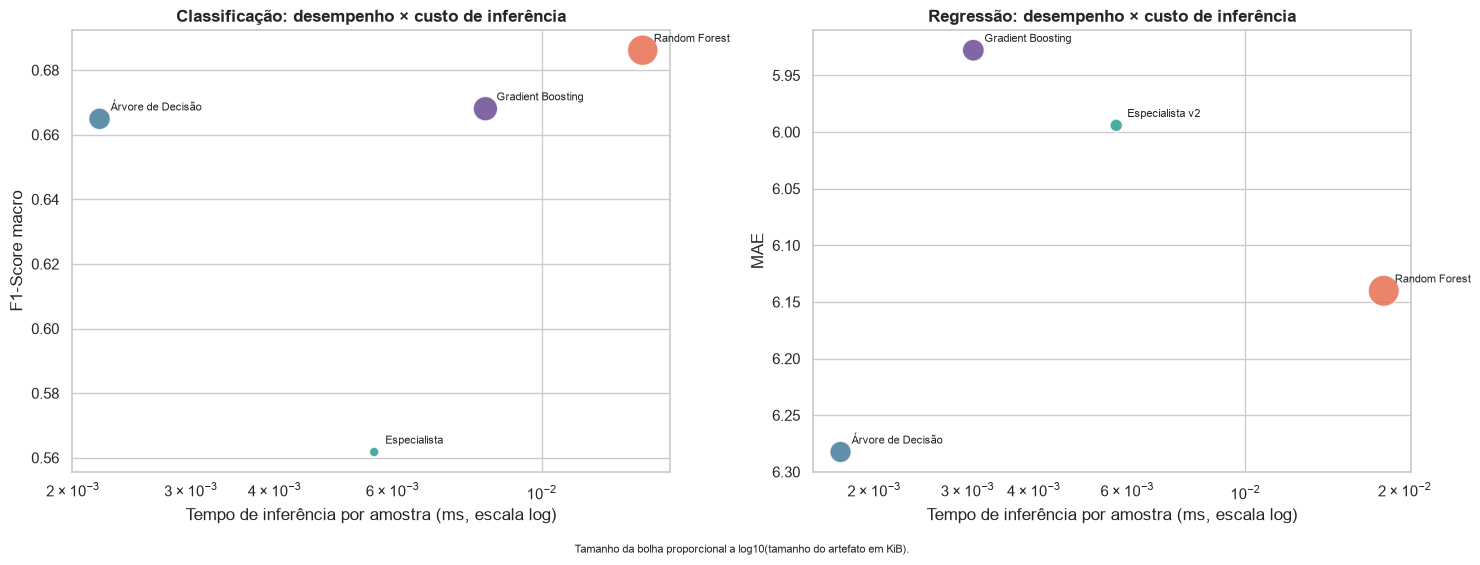

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))
cores = {
    "Especialista": "#2a9d8f",
    "Especialista v1": "#8ab17d",
    "Especialista v2": "#2a9d8f",
    "Árvore de Decisão": "#457b9d",
    "Random Forest": "#e76f51",
    "Gradient Boosting": "#6a4c93",
}

for eixo, problema, metrica, maior_melhor in [
    (eixos[0], "Classificação", "F1-Score macro", True),
    (eixos[1], "Regressão", "MAE", False),
]:
    sub = resumo[resumo["Problema"] == problema]
    tamanhos = 60 + 90 * np.log10(sub["Tamanho (KiB)"].clip(lower=0.5))
    eixo.scatter(
        sub["Tempo/amostra (ms)"],
        sub["Valor Teste"],
        s=tamanhos,
        c=[cores[m] for m in sub["Modelo"]],
        alpha=0.85,
        edgecolor="white",
        linewidth=1.2,
    )
    for _, linha in sub.iterrows():
        eixo.annotate(
            linha["Modelo"],
            (linha["Tempo/amostra (ms)"], linha["Valor Teste"]),
            textcoords="offset points",
            xytext=(8, 6),
            fontsize=8,
        )
    eixo.set_xscale("log")
    eixo.set_xlabel("Tempo de inferência por amostra (ms, escala log)")
    eixo.set_ylabel(metrica)
    eixo.set_title(
        f"{problema}: desempenho × custo de inferência", fontweight="bold"
    )
    if not maior_melhor:
        eixo.invert_yaxis()

fig.text(
    0.5,
    -0.02,
    "Tamanho da bolha proporcional a log10(tamanho do artefato em KiB).",
    ha="center",
    fontsize=8,
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tradeoff_final.png", dpi=300, bbox_inches="tight")
plt.show()

**Treinamento.** A árvore é a mais barata (0,32 s na classificação e
0,13 s na regressão). A Random Forest treina rápido (1,01 s e 1,55 s)
porque paraleliza as árvores, mas paga em tamanho. O Gradient Boosting é
sequencial e o mais caro na classificação (30,34 s, com 600 árvores);
na regressão são 6,27 s. Esses tempos são de **refit**, não incluem a
busca de hiperparâmetros.

**Inferência.** A árvore é a mais rápida (0,0014–0,0020 ms/amostra). O
especialista fica em 0,0049–0,0053 ms; o GB em 0,0031–0,0088 ms; a RF é
a mais lenta (0,0097 ms na classificação e 0,0160 ms na regressão). Em
lote de 10.000 registros, isso significa dezenas a centenas de
milissegundos — irrelevante para a maioria das aplicações, mas relevante
em altíssima frequência.

**Memória e tamanho.** O especialista é o menor artefato: 0,79 KiB
(classificação) e 1,95 KiB (regressão). A árvore fica em 131/115 KiB; o
GB em 775/157 KiB. A Random Forest é **cerca de 91× maior que o GB** na
classificação e **714× maior** na regressão (69,1 MiB e 109,4 MiB),
porque guarda 100/200 árvores profundas (823 mil e 1,59 milhão de nós).

**Energia.** O treinamento do GB consome 0,000548 kWh (classificação) e
0,000113 kWh (regressão). A inferência de 1 milhão de registros custa
entre 0,025 e 0,289 Wh, valor absoluto desprezível; porém, como a árvore
e a RF treinam em frações de segundo, essa inferência já equivale a
6,1–10,5× a energia de treino delas. No GB, a relação é de 29%
(classificação) e 49% (regressão).

**Trade-off.** Existe, mas não é linear. Na classificação, a RF troca
~91× o tamanho do GB por um ganho de F1 que não é claro; o GB entrega
quase o mesmo desempenho com 1/91 do tamanho e melhor CV. Na regressão, o
GB é ao mesmo tempo o melhor e um dos menores; a RF é a pior combinação
(maior, mais lenta, com overfitting). O especialista v2 é o menor e muito
competitivo, mas exige manutenção manual.

## 5. Pergunta (d) — custo de construção: regras versus treinamento de ML

O tempo das regras é humano (elaboração, testes e calibração); o tempo
dos modelos de ML é de CPU. A comparação abaixo usa o esforço humano
medido e o **refit** dos modelos finais medido no notebook 08.

In [7]:
def comparar_custos(problema, esforco_min):
    sub = resumo[(resumo["Problema"] == problema) & (resumo["Origem"] == "ML")]
    total_s = sub["Tempo Treino (s)"].sum()
    total_min = total_s / 60
    gb = sub[sub["Modelo"] == "Gradient Boosting"].iloc[0]
    gb_min = gb["Tempo Treino (s)"] / 60
    return {
        "Problema": problema,
        "Esforço humano (min)": esforco_min,
        "Treino ML total (min)": total_min,
        "Razão humano/ML total": esforco_min / total_min,
        "Treino GB (min)": gb_min,
        "Razão humano/GB": esforco_min / gb_min,
    }

custos = pd.DataFrame(
    [
        comparar_custos("Classificação", 152.45),
        comparar_custos("Regressão", 68.2167),
    ]
)
display(custos.round(2))

print("Limiar de inversão: o custo de ML precisaria ser multiplicado por")
for _, linha in custos.iterrows():
    print(
        f"  {linha['Problema']}: {linha['Razão humano/ML total']:.0f}x "
        "para igualar o esforço humano medido."
    )
print(
    "A busca de hiperparâmetros não foi cronometrada; esses limiares "
    "mostram quanto o refit subestima o custo real de ML."
)

,Problema,Esforço humano (min),Treino ML total (min),Razão humano/ML total,Treino GB (min),Razão humano/GB
0,Classificação,152.45,0.68,224.70,0.66,232.31
1,Regressão,68.22,0.16,434.28,0.13,525.93


Limiar de inversão: o custo de ML precisaria ser multiplicado por
  Classificação: 225x para igualar o esforço humano medido.
  Regressão: 434x para igualar o esforço humano medido.
A busca de hiperparâmetros não foi cronometrada; esses limiares mostram quanto o refit subestima o custo real de ML.


**Classificação.** O esforço humano foi de **152,45 min** (2,54 h) em
três sessões; o refit dos três modelos de ML somou 31,66 s (0,53 min).
A razão é de **~289×**; contra o GB isolado, ~301×. Mesmo que a busca de
hiperparâmetros (não cronometrada) multiplicasse o custo de ML por 100, o
total ficaria em ~53 min, ainda abaixo do esforço humano. Para inverter a
conclusão, a busca precisaria custar ~289× o refit — possível em grades
grandes, mas não observado.

**Regressão.** O esforço medido é de **68,22 min** (1,14 h), mas refere-se
à **v1 (4 regras)**, em uma única sessão. O refit dos modelos somou 7,95 s
(0,13 min), razão de **~515×**; contra o GB, ~653×. A v2 (19 faixas) não
foi cronometrada; como ela exigiu calibração OLS e mais regras, o custo
humano real é **maior** que 68,22 min. A conclusão qualitativa se mantém:
o custo dominante do especialista é humano, não computacional.

**Ressalva.** A comparação não é totalmente simétrica: o tempo humano
inclui ideação, validação clínica e iteração; o tempo de ML é apenas o
ajuste final. A conclusão válida é que, **neste dataset e com esta base de
regras**, o esforço humano é a parcela dominante. Ela não se generaliza
para bases de regras muito maiores nem para datasets em que o custo de
treinamento é proibitivo.

## 6. Pergunta (e) — interpretabilidade e explicabilidade

Interpretabilidade aqui significa conseguir **justificar uma decisão
individual**; explicabilidade inclui a possibilidade de auditar a lógica
global. O domínio é saúde (risco de diabetes), onde decisões afetam
pessoas e precisam ser contestáveis.

In [8]:
def resumo_regras(regras, nome):
    features = sorted({f for regra in regras for f in regra["condicoes"]})
    condicoes = np.mean([len(regra["condicoes"]) for regra in regras])
    return {
        "Base": nome,
        "Regras": len(regras),
        "Features usadas": len(features),
        "Média de condições/regra": condicoes,
        "Features": ", ".join(features),
    }

display(
    pd.DataFrame(
        [
            resumo_regras(REGRAS_CLASSIFICACAO, "Especialista (classificação)"),
            resumo_regras(REGRAS_REGRESSAO, "Especialista v2 (regressão)"),
        ]
    ).round(2)
)

print("Importância das features (RF e GB; maior = mais usada)")
display(importancias.set_index("Feature").round(3))

print("Features usadas nas regras versus importância na Random Forest")
display(comparacao_features.round(4))

,Base,Regras,Features usadas,Média de condições/regra,Features
0,Especialista (classificação),4,3,2.25,"Age, Fasting_Blood_Sugar, HbA1c"
1,Especialista v2 (regressão),19,8,1.00,"Age, BMI, Diet_Quality, Family_History_Diabete..."


Importância das features (RF e GB; maior = mais usada)


,RF classificação,GB classificação,RF regressão,GB regressão
Feature,,,,
Age,0.148,0.104,0.116,0.107
BMI,0.154,0.074,0.100,0.082
Diet_Quality,0.047,0.031,0.036,0.037
Family_History_Diabetes,0.052,0.106,0.109,0.120
Fasting_Blood_Sugar,0.302,0.369,0.344,0.355
HbA1c,0.204,0.234,0.216,0.217
Heart_Disease,0.031,0.026,NaN,NaN
Hypertension,0.032,0.032,0.039,0.044
PCOS,0.030,0.025,NaN,NaN


Features usadas nas regras versus importância na Random Forest


,Feature,Usada nas regras (classificação),Importância RF,Rank RF,Problema,Usada nas regras (regressão)
0,Fasting_Blood_Sugar,True,0.3018,1,Classificação,NaN
1,HbA1c,True,0.2036,2,Classificação,NaN
2,BMI,False,0.1543,3,Classificação,NaN
3,Age,True,0.1479,4,Classificação,NaN
4,Family_History_Diabetes,False,0.0521,5,Classificação,NaN
5,Diet_Quality,False,0.0471,6,Classificação,NaN
6,Hypertension,False,0.0316,7,Classificação,NaN
7,Heart_Disease,False,0.0314,8,Classificação,NaN
8,PCOS,False,0.0302,9,Classificação,NaN
9,Fasting_Blood_Sugar,NaN,0.3441,1,Regressão,True


**Especialista.** É a abordagem mais interpretável: cada decisão é uma
regra `SE ... ENTÃO ...` com limiares clínicos auditáveis. A classificação
usa 4 regras e apenas 3 variáveis (glicemia, HbA1c e idade); a regressão
v2 usa 19 faixas aditivas e 8 variáveis, com pontuação transparente. O
custo dessa transparência é a cobertura de 53,87% na classificação e a
necessidade de manutenção manual.

**Árvore de decisão.** É a melhor opção entre os modelos que aprendem:
profundidade 10, 735 folhas (classificação) e 792 (regressão). A árvore
completa não é legível, mas os primeiros níveis e as três regras
extraídas (ARV1–ARV3) são. É um bom **substituto interpretável** do
ensemble, com perda de desempenho.

**Random Forest e Gradient Boosting.** Não são diretamente
interpretáveis. A importância de features é global e não explica uma
previsão individual; seria necessário SHAP ou permutation importance
(não realizado). O GB é mais fácil de decompor (soma aditiva de árvores
rasas) que a RF, mas ambos exigem explicação post-hoc.

**A comparação com as regras.** Na classificação, as regras usam glicemia
(1ª no RF, 0,302), HbA1c (2ª, 0,204) e idade (4ª, 0,148); deixam de fora
o IMC (3ª, 0,154) e o histórico familiar (5ª, 0,052). Isso explica parte
do gap de desempenho: o ensemble captura sinal em variáveis que a base
não usa. Na regressão, as 8 variáveis das regras cobrem todo o conjunto e
as cinco primeiras importâncias (glicemia, HbA1c, idade, histórico e IMC)
são justamente as mais usadas; as regras estão bem alinhadas com o modelo.
A consistência entre RF e GB (glicemia e HbA1c sempre no topo) reforça que
os fatores dominantes são os mesmos — a diferença está nas interações e
nos limiares finos.

**Isso importa?** Sim. Em saúde, a explicabilidade é necessária para
validar decisões, detectar vieses e permitir contestação. Um modelo
opaco pode ter desempenho melhor, mas precisa vir acompanhado de
explicações e de um processo de governança. Para triagem automatizada de
baixo risco, um ensemble pode ser aceitável; para decisão clínica final,
especialista ou árvore são preferíveis.

## 7. Pergunta (f) — recomendação ao cliente

A recomendação separa **produção em servidor** de **restrição de
recursos/explicabilidade**. Ela assume que o cliente valoriza tanto o
desempenho quanto a possibilidade de auditar as decisões.

| Problema | Recomendação principal | Alternativa | Por quê |
|---|---|---|---|
| Classificação | **Gradient Boosting** | Árvore de decisão (explicabilidade/edge) ou especialista (triagem) | Melhor média de CV (0,7126), melhor accuracy (0,8790), F1 de teste praticamente empatado com a RF (0,6681 vs 0,6862, dentro do ruído) e artefato ~91× menor que a RF. |
| Regressão | **Gradient Boosting** | Especialista v2 (auditoria obrigatória) | Melhor MAE (5,9278) e R² (0,7745) no teste e na CV, gap pequeno (0,0461), inferência rápida e artefato de 157 KiB. O especialista v2 é quase tão bom (5,9941) e totalmente transparente. |

**Por que não a Random Forest?** Na classificação, ela tem o melhor F1
em uma única divisão, mas a vantagem não é clara, a CV é pior que a do GB
e o artefato é 69,1 MiB. Na regressão, ela overfitta (gap de MAE 1,55) e
é 714× maior que o GB. O custo não se justifica.

**Por que não o especialista como primeira escolha?** Na classificação,
ele deixa 46,13% dos casos sem resposta e tem F1 macro bem abaixo. Na
regressão, ele é competitivo, mas o custo de manutenção é humano e a v2
não foi cronometrada. Ele é a melhor escolha quando a explicabilidade é
requisito legal ou quando não há dados para treinar.

**Implantação sugerida.** Usar o GB como modelo principal, a árvore como
*surrogate* interpretável para explicar casos individuais e o
especialista como camada de validação clínica/sanity check. Monitorar
drift e reavaliar o especialista sempre que as diretrizes clínicas
mudarem.

## 8. Vantagens e desvantagens de cada abordagem

| Abordagem | Vantagens | Desvantagens |
|---|---|---|
| **Sistema especialista** | Totalmente auditável; não precisa de dados de treino; determinístico; artefato minúsculo (0,8–2 KiB); inferência barata; limiares clínicos justificáveis. | Elaboração manual cara (152 min na classificação); cobertura limitada (53,87%); limiares fixos não aprendem; difícil manter e escalar; conflitos exigem prioridade; não captura interações. |
| **Árvore de decisão** | Interpretável; treino e inferência muito rápidos; artefato pequeno (115–131 KiB); lida com não linearidade; boa linha de base. | Alta variância; instável a pequenas mudanças; overfitta sem poda (profundidade 25–35 sem ajuste); fronteiras axis-aligned; pior F1 macro. |
| **Random Forest** | Melhor F1 de teste na classificação; reduz variância por bagging; robusta; captura interações. | Artefato enorme (69,1–109,4 MiB); overfitting claro nos dados (gap 0,31/1,55); inferência mais lenta; baixa interpretabilidade; custo de memória. |
| **Gradient Boosting** | Melhor equilíbrio desempenho/custo; melhor CV nas duas tarefas; artefato compacto (157–775 KiB); inferência rápida; reduz viés sequencialmente. | Treino mais caro (30,34 s na classificação); sensível a hiperparâmetros; menos interpretável; pode overfittar com muitas árvores. |
| **Especialista v2 (regressão)** | Transparente; 19 faixas aditivas; MAE próximo do GB; artefato de 2 KiB; sem dependência de biblioteca de ML. | Pesos calibrados manualmente/OLS; estrutura aditiva não captura interações; manutenção manual; custo humano não totalmente cronometrado. |

## 9. Limitações do estudo

* **Uma única divisão treino/teste.** A CV de 5 folds reduz o risco de
  conclusões baseadas em sorte, mas os folds vêm do mesmo dataset; não há
  validação externa.
* **Tamanho e desbalanceamento.** A classe *Low* tem menos de 1% do teste;
  as métricas macro são sensíveis a poucos casos. O especialista não
  cobre 46,13% dos registros, o que limita a comparação direta.
* **Qualidade das regras.** Os limiares vêm da ADA e de estatísticas do
  treino; a v2 foi calibrada por OLS no treino, mas não passou por
  validação clínica. As regras de classificação usam apenas 3 variáveis e
  ignoram IMC e histórico familiar, que o ensemble considera relevantes.
* **Custo de ML subestimado.** O tempo do notebook 08 é de refit; a busca
  de hiperparâmetros não foi cronometrada. O custo real de construção dos
  modelos é maior que o reportado.
* **Cronometragem humana incompleta.** A regressão tem 1 sessão (v1);
  faltam 2 sessões e a v2 não foi cronometrada. O esforço de 68,22 min é
  um limite inferior.
* **Energia e CO₂ estimados.** Usam 65 W e 45,8 gCO₂/kWh, não medição de
  parede; servem para comparação relativa.
* **Importância de features.** A importância por impureza é global e
  favorece variáveis contínuas; não foi feita permutation importance nem
  SHAP. As conclusões sobre explicabilidade são qualitativas.
* **Hardware único.** Os tempos dependem do i5-13420H, 7,7 GB de RAM e
  Windows 11; não devem ser extrapolados para outras máquinas.
* **Sem teste estatístico formal.** A comparação usa a razão entre
  diferença e desvio padrão da CV, não um teste pareado sobre os folds.

## 10. Síntese final

* **Classificação:** Random Forest e Gradient Boosting empatam em
  desempenho; o GB é mais consistente na CV, muito menor e mais rápido.
  O especialista é interpretável, mas cobre 53,87% e erra *Moderate*.
* **Regressão:** Gradient Boosting é o melhor (MAE 5,9278; R² 0,7745); o
  especialista v2 é quase tão bom (5,9941; R² 0,7655), minúsculo e
  transparente. A v1 é inadequada.
* **Generalização:** GB e especialista v2 têm os menores gaps; RF
  overfitta; árvore fica no meio.
* **Eficiência:** a árvore é a mais rápida; especialista e GB ficam na mesma ordem de grandeza; a RF é a mais lenta;
  RF é ordens de grandeza maior em disco. O custo do especialista é
  humano, não computacional.
* **Recomendação:** GB como modelo principal nos dois problemas; árvore
  como explicador local/*surrogate*; especialista como camada de
  auditoria e validação clínica. Em restrição de recursos ou exigência de
  explicabilidade, árvore (classificação) e especialista v2 (regressão).

### Arquivos produzidos por este notebook

* `reports/tables/resumo_final.csv` — tabela comparativa completa.
* `reports/figures/tradeoff_final.png` — desempenho × custo de inferência.

### Ordem de execução do projeto

`03_expert_system.ipynb` → `04_decision_tree.ipynb` →
`05_ensemble.ipynb` → `06_evaluation_metrics.ipynb` →
`07_generalization.ipynb` → `08_computational_efficiency.ipynb` →
`09_comparative_analysis.ipynb`.

A semente global é `RANDOM_STATE = 42`; o pré-processamento é ajustado
dentro do pipeline, apenas no treino de cada fold, e o teste não participa
da elaboração das regras nem da escolha de hiperparâmetros.